2025-08-16 07:35:49.848763: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1755329750.030144      36 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1755329750.082789      36 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
I0000 00:00:1755329762.340344      36 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 15513 MB memory:  -> device: 0, name: Tesla P100-PCIE-16GB, pci bus id: 0000:00:04.0, compute capability: 6.0


80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/models/functional.py:237: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['keras_tensor']
Received: inputs=Tensor(shape=(3, 400, 400, 3))
  warnings.warn(msg)
I0000 00:00:1755329766.230322      94 cuda_dnn.cc:529] Loaded cuDNN version 90300


Iteration 0, loss=4.932460701810688e+16


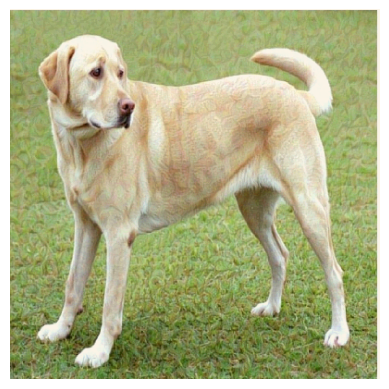

Iteration 100, loss=301632600408064.0


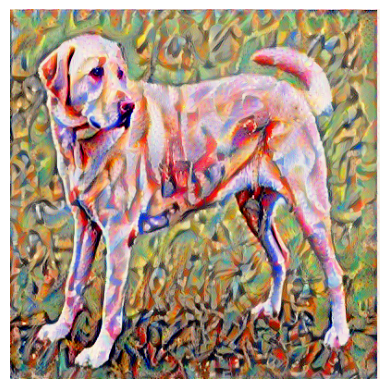

Iteration 200, loss=122129995530240.0


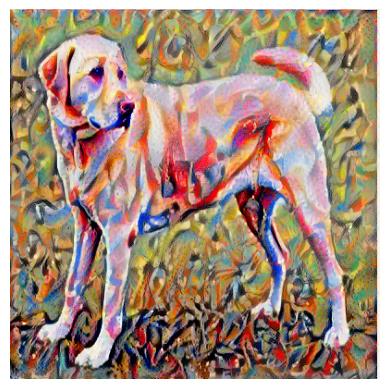

Iteration 300, loss=72069215682560.0


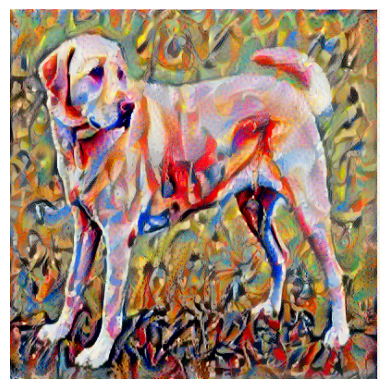

Iteration 400, loss=45241780404224.0


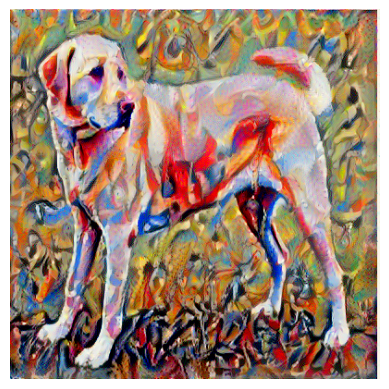

Iteration 500, loss=33298503958528.0


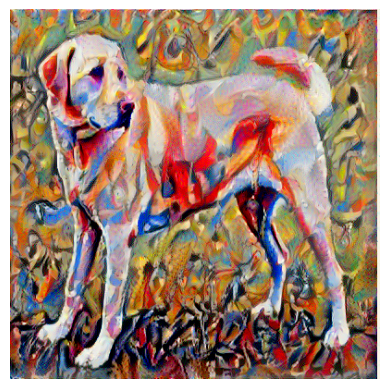

Iteration 600, loss=25441318469632.0


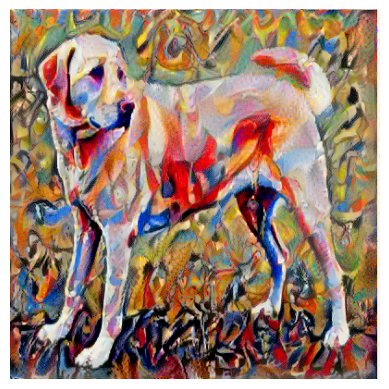

Iteration 700, loss=49618972835840.0


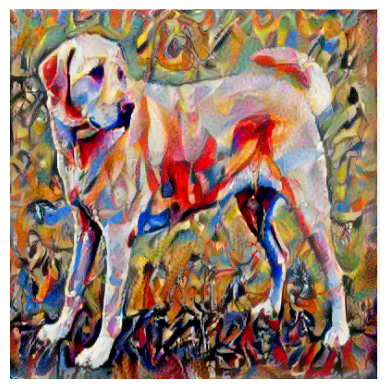

Iteration 800, loss=17982677843968.0


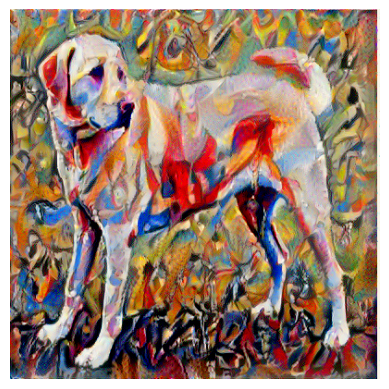

Iteration 900, loss=14998468296704.0


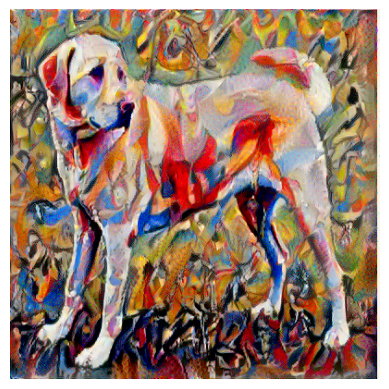

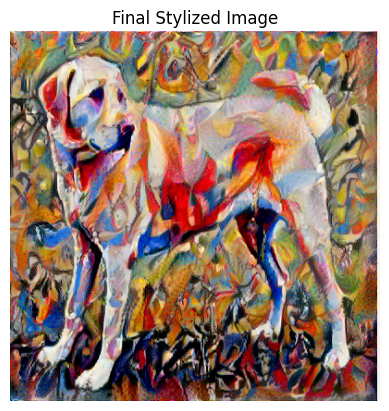

In [1]:
# ================================
# Project : Neural Style Transfer
# ================================

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.applications import vgg19
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras import backend as K

# Step 1: Helper Functions
def preprocess_image(img_path, target_size=(400, 400)):
    img = load_img(img_path, target_size=target_size)
    img = img_to_array(img)
    img = np.expand_dims(img, axis=0)
    img = vgg19.preprocess_input(img)
    return tf.convert_to_tensor(img)

def deprocess_image(x):
    x = x.reshape((x.shape[1], x.shape[2], 3))
    # undo VGG19 preprocessing
    x[:, :, 0] += 103.939
    x[:, :, 1] += 116.779
    x[:, :, 2] += 123.68
    x = x[:, :, ::-1]  # BGR → RGB
    x = np.clip(x, 0, 255).astype("uint8")
    return x

# Step 2: Load Content and Style Images
content_path = "/kaggle/input/stylledata/WhatsApp Image 2025-08-16 at 12.43.05_8d57e00e.jpg"  
style_path = "/kaggle/input/stylledata/WhatsApp Image 2025-08-16 at 12.42.58_c16f6c93.jpg"  

content_image = preprocess_image(content_path)
style_image = preprocess_image(style_path)

# Step 3: Define Model
model = vgg19.VGG19(weights="imagenet", include_top=False)
model.trainable = False

# Chosen layers
content_layer = "block5_conv2"
style_layers = [
    "block1_conv1",
    "block2_conv1",
    "block3_conv1",
    "block4_conv1",
    "block5_conv1",
]

# Step 4: Extract Features
outputs = [model.get_layer(name).output for name in style_layers + [content_layer]]
feature_extractor = tf.keras.Model([model.input], outputs)

def gram_matrix(x):
    x = tf.transpose(x, (0, 3, 1, 2))
    features = tf.reshape(x, (tf.shape(x)[0], tf.shape(x)[1], -1))
    gram = tf.matmul(features, features, transpose_b=True)
    return gram

# Step 5: Compute Loss
def compute_loss(combination_image, content_image, style_image):
    input_tensor = tf.concat([content_image, style_image, combination_image], axis=0)
    features = feature_extractor(input_tensor)
    
    style_features = features[:len(style_layers)]
    content_features = features[len(style_layers):]
    
    loss = tf.zeros(())
    style_weight = 1e-2
    content_weight = 1e4
    
    # Content loss
    base_content = content_features[-1][0]
    target_content = content_features[-1][2]
    loss += content_weight * tf.reduce_mean(tf.square(base_content - target_content))
    
    # Style loss
    for i, style_feature in enumerate(style_features):
        gram_s = gram_matrix(style_feature[1:2])
        gram_c = gram_matrix(style_feature[2:3])
        loss += style_weight * tf.reduce_mean(tf.square(gram_s - gram_c))
    
    return loss

# Step 6: Optimize
generated_image = tf.Variable(content_image, dtype=tf.float32)

optimizer = tf.optimizers.Adam(learning_rate=5.0)

@tf.function
def train_step():
    with tf.GradientTape() as tape:
        loss = compute_loss(generated_image, content_image, style_image)
    grad = tape.gradient(loss, generated_image)
    optimizer.apply_gradients([(grad, generated_image)])
    generated_image.assign(tf.clip_by_value(generated_image, -127.5, 127.5))
    return loss

# Step 7: Run Optimization
epochs = 1000
for i in range(epochs):
    loss = train_step()
    if i % 100 == 0:
        print(f"Iteration {i}, loss={loss}")
        img = deprocess_image(generated_image.numpy())
        plt.imshow(img)
        plt.axis("off")
        plt.show()

# Final Result
final_img = deprocess_image(generated_image.numpy())
plt.imshow(final_img)
plt.axis("off")
plt.title("Final Stylized Image")
plt.show()
